<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ Datathon 2026 - Task 1: Peramalan Kecepatan Lalu Lintas ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Peramalan kecepatan 1.260 segmen jalan pada horizon +20, +40, dan +60 menit</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **TrafficCast v1**

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Prapemrosesan dan Feature Engineering**](#4)
5. [**Pemodelan**](#5)
6. [**Inferensi dan Submisi**](#6)
7. [**Pasca-Analisis**](#7)
8. [**Daftar Pustaka**](#8)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Lalu lintas kota tidak bergerak acak. Ia merespons struktur jaringan jalan, waktu dalam hari, dan peristiwa yang terjadi di lapangan seperti kecelakaan, penutupan jalan, dan konstruksi. Pada Task 1 ini, peserta diminta meramalkan kecepatan lalu lintas berdasarkan tiga sumber sinyal sekaligus:

1. **Riwayat kecepatan**: jendela 15 *timestep* (1 jam, resolusi 4 menit) untuk seluruh 1.260 segmen jalan.
2. **Teks peristiwa**: deskripsi bahasa natural tentang kejadian di jaringan jalan pada saat itu.
3. **Jaringan jalan**: matriks *adjacency* 1.260 x 1.260 beserta geometri dan metadata tiap segmen.

- **Tugas**: meramalkan kecepatan (km/jam) tiap segmen jalan pada horizon `h5` (+20 menit), `h10` (+40 menit), dan `h15` (+60 menit)
- **Metrik**: *Mean Squared Error* (MSE), dirata-ratakan lintas seluruh sampel, horizon, dan segmen
- **Format submisi**: satu baris per kombinasi (sampel, horizon, jalan) dengan id berpola `test_{sample}_h{horizon}_r{road}`, urutan id wajib mengikuti `sample_submission.csv` persis
- **Platform**: Kaggle Notebook, GPU T4 x2

---

## Dataset

*Dataset* terdiri dari dua blok deret waktu kontinu untuk *training* (blok `m1` sepanjang 11.160 *timestep*, tepat 31 hari, dan blok `m2` sepanjang 5.039 *timestep*, sekitar 14 hari), masing-masing disertai teks peristiwa per *timestep*. Data *test* berisi 540 jendela riwayat berukuran 15 *timestep* x 1.260 jalan beserta satu teks peristiwa per sampel. Berkas statis memuat *adjacency matrix* antar segmen, geometri jalan (`Roads1260.json`), dan *mask* segmen aktif. Seluruh klaim mengenai *shape*, tipe data, dan isi berkas diverifikasi langsung pada bagian Analisis Data Eksploratif, bukan diasumsikan.

---

## Pendekatan: *Gradient Boosting* (LightGBM) + Fitur Spasial-Temporal + Aturan Nol

Dengan anggaran waktu ronde hanya 5 jam, prioritas utama adalah satu *pipeline* yang pasti selesai dan menghasilkan submisi valid. Kami memilih **LightGBM** (satu model per horizon) di atas fitur hasil rekayasa, dengan tiga pertimbangan:

1. **Risiko rendah, diagnosis mudah**. Model *gradient boosting* pada data tabular berukuran jutaan baris terlatih dalam hitungan menit di CPU Kaggle, tanpa risiko *out-of-memory* GPU, tanpa sensitivitas terhadap *learning rate schedule*, dan dengan *feature importance* yang bisa diperiksa langsung.
2. **Ketiga sumber sinyal tetap terpakai** dalam bentuk ringan: riwayat kecepatan menjadi fitur *lag* dan statistik jendela, graf jalan menjadi fitur agregat tetangga (rata-rata kecepatan tetangga masuk dan keluar), dan teks peristiwa menjadi fitur hitungan kata kunci per tipe kejadian.
3. **Karakteristik data mendukung**. EDA singkat (bagian 3) menunjukkan nilai nol pada deret kecepatan bersifat blok dan persisten sempurna, sehingga dapat ditangani aturan deterministik sederhana, sementara sinyal jangka pendek didominasi level dan tren lokal yang justru merupakan kekuatan fitur tabular.

Alternatif model sekuens/graf (GRU, GNN ringan) berpotensi menangkap dinamika spasial-temporal lebih kaya, tetapi lebih rawan *bug*, lebih lama dilatih, dan lebih berisiko tidak selesai dalam sisa waktu. Keputusan ini dicatat kembali di Pasca-Analisis sebagai kandidat iterasi v2.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

In [1]:
!nvidia-smi

Sat Jul 18 05:45:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, platform, sys
print('Python :', sys.version)
print('OS     :', platform.system(), platform.release())
print('CWD    :', os.getcwd())

Python : 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
OS     : Linux 6.12.90+
CWD    : /kaggle/working


---

## Instalasi

Seluruh pustaka yang dipakai *notebook* ini (NumPy, pandas, Matplotlib, LightGBM) sudah tersedia pada *image* default Kaggle, sehingga tidak diperlukan instalasi tambahan. Ini disengaja agar *notebook* tetap bisa berjalan penuh meskipun akses internet Kaggle dimatikan.

---

## Imports dan Seed

Seluruh sumber keacakan dikunci dengan satu *seed* global agar hasil dapat direproduksi.

In [3]:
import json, random, re, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

print('numpy   :', np.__version__)
print('pandas  :', pd.__version__)
print('lightgbm:', lgb.__version__)

numpy   : 2.0.2
pandas  : 2.3.3
lightgbm: 4.6.0


---

## Konfigurasi

Seluruh *hyperparameter*, konstanta data, dan konfigurasi *run* dipusatkan pada satu kelas `Settings` agar mudah diaudit dan diubah antar iterasi.

In [4]:
class Settings:
    SEED          = 42

    # Konstanta data
    N_ROADS       = 1260
    N_TEST        = 540
    HIST_LEN      = 15          # panjang jendela riwayat (1 jam, 4 menit per timestep)
    HORIZONS      = [5, 10, 15] # +20, +40, +60 menit (dalam timestep)
    STEPS_PER_DAY = 360         # 24 jam x 60 menit / 4 menit

    # Pembentukan sampel training
    WINDOW_STRIDE = 5           # jarak antar ujung jendela training
    VAL_FRACTION  = 0.15        # porsi jendela terakhir tiap blok untuk validasi
    VAL_GAP       = 30          # jeda timestep antara train dan val (riwayat 15 + horizon 15)

    # Kata kunci tipe peristiwa dari teks (hasil inspeksi kosakata pada EDA)
    KEYWORDS = ['road closure', 'accident', 'construction',
                'traffic control', 'prohibit', 'announcement']

    # LightGBM (satu model per horizon)
    LGB_PARAMS = dict(
        objective='regression', metric='l2',
        learning_rate=0.05, num_leaves=127, min_data_in_leaf=200,
        feature_fraction=0.9, bagging_fraction=0.8, bagging_freq=1,
        lambda_l2=1.0, num_threads=os.cpu_count(), seed=42, verbosity=-1,
    )
    NUM_BOOST_ROUND = 1200
    EARLY_STOPPING  = 75

    # Pasca-pemrosesan prediksi
    CLIP_MAX = 150.0            # sedikit di atas kecepatan maksimum yang teramati di train

set_seed(Settings.SEED)

---

## Deteksi Path

*Notebook* mendeteksi *environment* secara otomatis: saat berjalan di Kaggle, path mengarah ke *dataset* kompetisi; saat berjalan lokal, path mengarah ke folder `dataset/` di *root* proyek. Keberadaan seluruh berkas diverifikasi sebelum melangkah lebih jauh.

In [5]:
IS_KAGGLE = Path('/kaggle/input').exists()
DATA_ROOT = Path('/kaggle/input/competitions/datathon-task-1/dataset-task1') if IS_KAGGLE else Path('dataset')
WORK_DIR  = Path('/kaggle/working') if IS_KAGGLE else Path('.')

PATHS = {
    'train_speed_m1': DATA_ROOT / 'train'  / 'train_speed_m1_1_11160.npy',
    'train_speed_m2': DATA_ROOT / 'train'  / 'train_speed_m2_1_5039.npy',
    'train_text_m1' : DATA_ROOT / 'train'  / 'train_text_m1_1_11160.json',
    'train_text_m2' : DATA_ROOT / 'train'  / 'train_text_m2_1_5039.json',
    'test_hist'     : DATA_ROOT / 'test'   / 'test_X_hist.npy',
    'test_texts'    : DATA_ROOT / 'test'   / 'test_texts.json',
    'adjacency'     : DATA_ROOT / 'static' / 'matrix.npy',
    'roads_meta'    : DATA_ROOT / 'static' / 'Roads1260.json',
    'active_mask'   : DATA_ROOT / 'static' / 'active_mask.npy',
    'sample_sub'    : DATA_ROOT / 'sample_submission.csv',
}

print('Environment :', 'Kaggle' if IS_KAGGLE else 'Lokal')
for name, p in PATHS.items():
    print(f"  {name:15s} {'OK    ' if p.exists() else 'HILANG'} {p}")
assert all(p.exists() for p in PATHS.values()), "Ada berkas data yang tidak ditemukan, periksa DATA_ROOT."

Environment : Kaggle
  train_speed_m1  OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/train/train_speed_m1_1_11160.npy
  train_speed_m2  OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/train/train_speed_m2_1_5039.npy
  train_text_m1   OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/train/train_text_m1_1_11160.json
  train_text_m2   OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/train/train_text_m2_1_5039.json
  test_hist       OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/test/test_X_hist.npy
  test_texts      OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/test/test_texts.json
  adjacency       OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/static/matrix.npy
  roads_meta      OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/static/Roads1260.json
  active_mask     OK     /kaggle/input/competitions/datathon-task-1/dataset-task1/static/active_mask.npy
  samp

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Verifikasi Struktur Data

Langkah pertama adalah memastikan *shape*, tipe data, rentang nilai, dan konsistensi antar berkas, sebelum satu baris kode pemodelan pun ditulis.

In [6]:
speed_m1  = np.load(PATHS['train_speed_m1'])
speed_m2  = np.load(PATHS['train_speed_m2'])
test_hist = np.load(PATHS['test_hist'])
adj       = np.load(PATHS['adjacency'])
active    = np.load(PATHS['active_mask'])
roads_meta = json.load(open(PATHS['roads_meta']))
sample_sub = pd.read_csv(PATHS['sample_sub'])

raw_text_m1 = json.load(open(PATHS['train_text_m1']))
raw_text_m2 = json.load(open(PATHS['train_text_m2']))
raw_text_te = json.load(open(PATHS['test_texts']))

def _ordered(d):
    return [d[k] for k in sorted(d, key=lambda s: int(s.split('_')[-1]))]

texts_m1 = _ordered(raw_text_m1)
texts_m2 = _ordered(raw_text_m2)
texts_te = _ordered(raw_text_te)

for name, a in [('speed_m1', speed_m1), ('speed_m2', speed_m2),
                ('test_hist', test_hist), ('adjacency', adj), ('active_mask', active)]:
    print(f"{name:12s} shape={str(a.shape):18s} dtype={str(a.dtype):8s} "
          f"min={a.min():.1f} max={a.max():.1f}")

print(f"\nteks: m1={len(texts_m1)}, m2={len(texts_m2)}, test={len(texts_te)}")
print(f"roads_meta: {len(roads_meta)} segmen")
print(f"sample_submission: {sample_sub.shape}")
print(sample_sub.head(3).to_string(index=False))

assert speed_m1.shape[1] == speed_m2.shape[1] == Settings.N_ROADS
assert test_hist.shape == (Settings.N_TEST, Settings.HIST_LEN, Settings.N_ROADS)
assert len(texts_m1) == len(speed_m1) and len(texts_m2) == len(speed_m2)
assert len(texts_te) == Settings.N_TEST
assert len(sample_sub) == Settings.N_TEST * len(Settings.HORIZONS) * Settings.N_ROADS
print('\nSeluruh dimensi konsisten dengan deskripsi kompetisi.')

speed_m1     shape=(11160, 1260)      dtype=float32  min=0.0 max=142.0
speed_m2     shape=(5039, 1260)       dtype=float32  min=0.0 max=151.0
test_hist    shape=(540, 15, 1260)    dtype=float32  min=0.0 max=137.0
adjacency    shape=(1260, 1260)       dtype=int8     min=0.0 max=1.0
active_mask  shape=(1296,)            dtype=bool     min=0.0 max=1.0

teks: m1=11160, m2=5039, test=540
roads_meta: 1260 segmen
sample_submission: (2041200, 2)
              id  speed
test_00000_h5_r0    0.0
test_00000_h5_r1    0.0
test_00000_h5_r2    0.0

Seluruh dimensi konsisten dengan deskripsi kompetisi.


> ### Insights
> Seluruh berkas konsisten: 1.260 segmen di semua sumber, teks selaras satu-satu dengan *timestep* (train) dan sampel (test), dan `sample_submission` berisi tepat 540 x 3 x 1.260 = 2.041.200 baris. Blok `m1` berdurasi 11.160 *timestep* = tepat 31 hari pada resolusi 4 menit, sehingga `STEPS_PER_DAY = 360` terkonfirmasi. Horizon `h5/h10/h15` berarti 5, 10, dan 15 *timestep* ke depan.

---

## Pola Temporal

Kita periksa dinamika rata-rata jaringan selama beberapa hari serta profil rata-rata per jam dalam sehari (dihitung hanya dari nilai bukan nol agar tidak terdistorsi *outage* sensor).

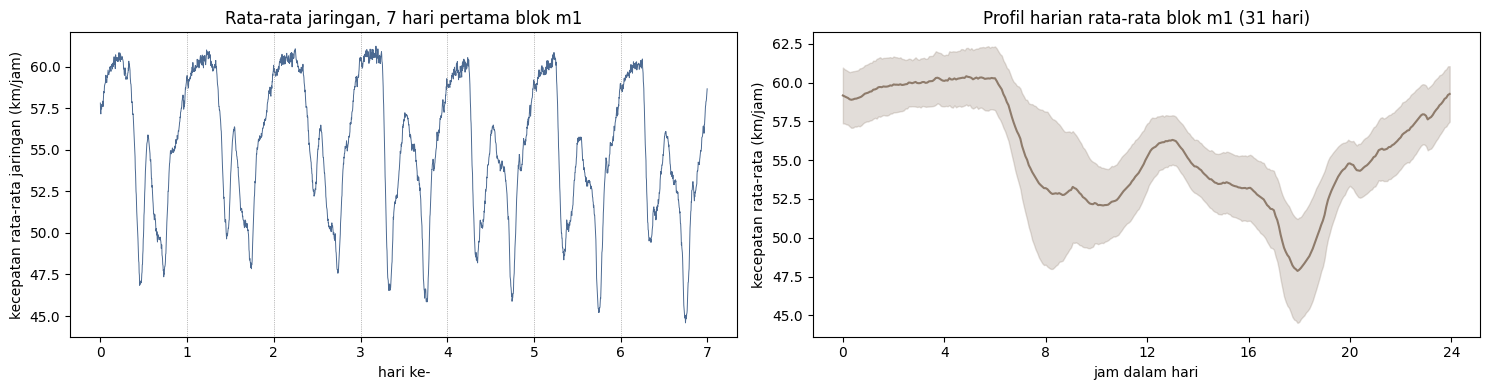

autokorelasi lag 1 timestep : 0.947
autokorelasi lag 1 hari     : 0.870


In [7]:
nz_m1 = np.where(speed_m1 > 0, speed_m1, np.nan)
net_mean = np.nanmean(nz_m1, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
days = 7 * Settings.STEPS_PER_DAY
axes[0].plot(np.arange(days) / Settings.STEPS_PER_DAY, net_mean[:days], lw=0.7, color='#4C6A92')
axes[0].set_xlabel('hari ke-'); axes[0].set_ylabel('kecepatan rata-rata jaringan (km/jam)')
axes[0].set_title('Rata-rata jaringan, 7 hari pertama blok m1')
for d in range(1, 7):
    axes[0].axvline(d, color='gray', lw=0.5, ls=':')

profile = net_mean.reshape(-1, Settings.STEPS_PER_DAY)
prof_mean, prof_std = profile.mean(0), profile.std(0)
jam = np.arange(Settings.STEPS_PER_DAY) * 4 / 60
axes[1].plot(jam, prof_mean, color='#8E7B6B', lw=1.5)
axes[1].fill_between(jam, prof_mean - prof_std, prof_mean + prof_std, alpha=0.25, color='#8E7B6B')
axes[1].set_xlabel('jam dalam hari'); axes[1].set_ylabel('kecepatan rata-rata (km/jam)')
axes[1].set_title('Profil harian rata-rata blok m1 (31 hari)')
axes[1].set_xticks(range(0, 25, 4))
plt.tight_layout(); plt.show()

acf_1  = np.corrcoef(speed_m1[:-1].ravel()[::37],  speed_m1[1:].ravel()[::37])[0, 1]
acf_1d = np.corrcoef(speed_m1[:-360].ravel()[::37], speed_m1[360:].ravel()[::37])[0, 1]
print(f'autokorelasi lag 1 timestep : {acf_1:.3f}')
print(f'autokorelasi lag 1 hari     : {acf_1d:.3f}')

> ### Insights
> Siklus harian sangat kuat: kecepatan anjlok pada jam sibuk pagi dan sore dan autokorelasi pada *lag* satu hari mencapai sekitar 0,87. Namun jendela riwayat *test* hanya 1 jam dan tidak disertai *timestamp*, sehingga posisi dalam siklus harian tidak diketahui secara langsung. Autokorelasi *lag* pendek yang sangat tinggi (0,95) menunjukkan level dan tren lokal dari jendela riwayat adalah sinyal utama yang dapat diandalkan untuk horizon 20-60 menit. Estimasi fase harian dari bentuk jendela sempat diuji terpisah dan terbukti tidak stabil, dicatat sebagai ide v2 di Pasca-Analisis.

---

## Distribusi Kecepatan dan Anomali Nol

Nilai minimum 0 pada ketiga sumber kecepatan perlu dicurigai sebagai data hilang (*sensor outage*), bukan kecepatan sesungguhnya. Kita ukur seberapa banyak dan bagaimana perilakunya terhadap waktu.

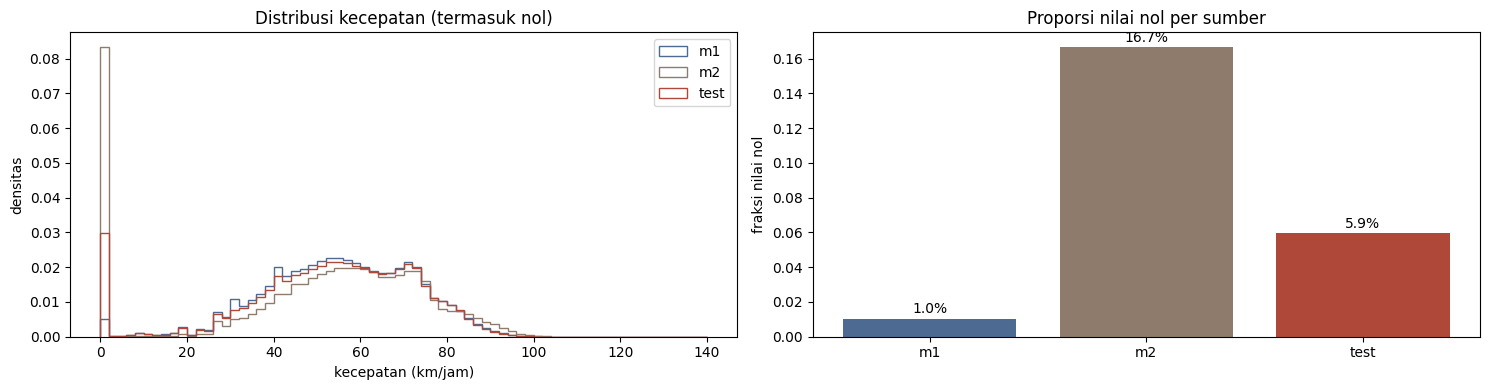

Persistensi nol (blok m2, blok m1 serupa):
  h= 5: P(target=0 | nilai kini = 0) = 0.9998 | P(target=0 | nilai kini > 0) = 0.00003
  h=10: P(target=0 | nilai kini = 0) = 0.9998 | P(target=0 | nilai kini > 0) = 0.00005
  h=15: P(target=0 | nilai kini = 0) = 0.9997 | P(target=0 | nilai kini > 0) = 0.00005


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
bins = np.linspace(0, 140, 71)
for arr, name, c in [(speed_m1, 'm1', '#4C6A92'), (speed_m2, 'm2', '#8E7B6B'),
                     (test_hist, 'test', '#B0483A')]:
    axes[0].hist(arr.ravel()[::17], bins=bins, density=True, histtype='step', lw=1.4, label=name, color=c)
axes[0].set_xlabel('kecepatan (km/jam)'); axes[0].set_ylabel('densitas')
axes[0].set_title('Distribusi kecepatan (termasuk nol)'); axes[0].legend()

zf = [(speed_m1 == 0).mean(), (speed_m2 == 0).mean(), (test_hist == 0).mean()]
axes[1].bar(['m1', 'm2', 'test'], zf, color=['#4C6A92', '#8E7B6B', '#B0483A'])
for i, v in enumerate(zf):
    axes[1].text(i, v + 0.003, f'{v:.1%}', ha='center')
axes[1].set_ylabel('fraksi nilai nol'); axes[1].set_title('Proporsi nilai nol per sumber')
plt.tight_layout(); plt.show()

print('Persistensi nol (blok m2, blok m1 serupa):')
for h in Settings.HORIZONS:
    z = speed_m2[:-h] == 0
    p00 = (speed_m2[h:][z] == 0).mean()
    p0x = (speed_m2[h:][~z] == 0).mean()
    print(f'  h={h:2d}: P(target=0 | nilai kini = 0) = {p00:.4f} | '
          f'P(target=0 | nilai kini > 0) = {p0x:.5f}')

> ### Insights
> Nilai nol bukan kemacetan total, melainkan blok data hilang: jika sebuah jalan bernilai nol pada *timestep* terakhir riwayat, targetnya nol pada semua horizon dengan probabilitas hampir 1, dan sebaliknya jalan yang hidup hampir tidak pernah tiba-tiba menjadi nol. Ini melahirkan **aturan nol** deterministik: prediksi 0 untuk jalan yang bernilai 0 di akhir riwayat, dan latih model hanya pada baris yang hidup. Blok `m2` (16,7% nol) tetap dipakai karena mayoritas barisnya valid.

---

## Baseline Naif

Sebelum membangun model, kita ukur dua peramal paling sederhana pada seluruh deret *train*: *persistence* (nilai terakhir) dan rata-rata 3 *timestep* terakhir. Angka ini menjadi patokan bawah yang wajib dikalahkan model.

In [9]:
rows = []
for h in Settings.HORIZONS:
    for name, pred_fn in [
        ('persistence', lambda a, h: a[Settings.HIST_LEN - 1:-h]),
        ('mean3',       lambda a, h: (a[Settings.HIST_LEN - 1:-h]
                                      + a[Settings.HIST_LEN - 2:-h - 1]
                                      + a[Settings.HIST_LEN - 3:-h - 2]) / 3),
    ]:
        errs = []
        for a in (speed_m1, speed_m2):
            e = pred_fn(a, h) - a[Settings.HIST_LEN - 1 + h:]
            errs.append((e ** 2).ravel())
        rows.append({'horizon': f'h{h}', 'baseline': name,
                     'MSE': float(np.mean(np.concatenate(errs)))})

baseline_df = pd.DataFrame(rows).pivot(index='baseline', columns='horizon', values='MSE')
baseline_df = baseline_df[['h5', 'h10', 'h15']]
print(baseline_df.round(2).to_string())

horizon         h5    h10    h15
baseline                        
mean3        40.11  50.05  57.41
persistence  48.46  59.28  66.83


> ### Insights
> Rata-rata 3 *timestep* terakhir mengalahkan *persistence* dengan selisih besar pada semua horizon, artinya deret mengandung *noise* jangka pendek yang layak dihaluskan. MSE juga naik wajar seiring horizon. Model kita harus jelas lebih baik dari baris `mean3` ini pada validasi, kalau tidak, ada yang salah.

---

## Struktur Graf Jalan

Matriks *adjacency* menghubungkan segmen-segmen jalan. Kita periksa derajatnya dan petakan posisi geografis segmen (dari `Roads1260.json`) diwarnai kecepatan rata-ratanya.

simetris: False | tepi (tanpa self-loop): 3862 | derajat keluar rata-rata: 3.07


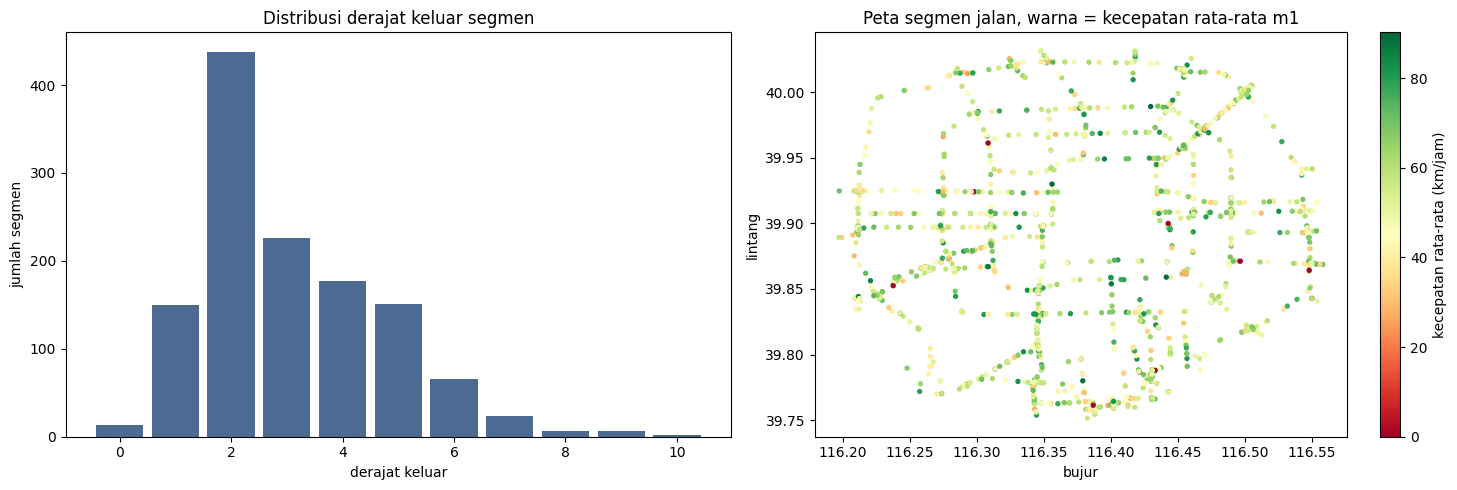

In [10]:
A_raw = adj.astype(np.float32)
np.fill_diagonal(A_raw, 0)
outdeg_v, indeg_v = A_raw.sum(1), A_raw.sum(0)
print(f'simetris: {bool((adj == adj.T).all())} | tepi (tanpa self-loop): {int(A_raw.sum())} | '
      f'derajat keluar rata-rata: {outdeg_v.mean():.2f}')

road_lon = np.array([r[0]['coordList'][0] for r in roads_meta])
road_lat = np.array([r[0]['coordList'][1] for r in roads_meta])
road_speed_mean = np.nan_to_num(np.nanmean(nz_m1, axis=0))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(outdeg_v, bins=np.arange(0, 12) - 0.5, color='#4C6A92', rwidth=0.85)
axes[0].set_xlabel('derajat keluar'); axes[0].set_ylabel('jumlah segmen')
axes[0].set_title('Distribusi derajat keluar segmen')

sc = axes[1].scatter(road_lon, road_lat, c=road_speed_mean, s=8, cmap='RdYlGn')
plt.colorbar(sc, ax=axes[1], label='kecepatan rata-rata (km/jam)')
axes[1].set_xlabel('bujur'); axes[1].set_ylabel('lintang')
axes[1].set_title('Peta segmen jalan, warna = kecepatan rata-rata m1')
plt.tight_layout(); plt.show()

> ### Insights
> Jaringan tersambung renggang (rata-rata sekitar 4 tetangga per segmen) dan peta memperlihatkan struktur jalan lingkar dan arteri dengan rezim kecepatan yang berbeda-beda per lokasi. Dua hal ini memotivasi dua kelompok fitur murah: statistik historis per segmen (rezim khas tiap jalan) dan agregat kecepatan tetangga via perkalian matriks *adjacency* ternormalisasi, tanpa perlu GNN.

---

## Teks Peristiwa

Kita bedah kosakata teks: tipe peristiwa apa saja yang muncul, dan seberapa padat per entri, untuk memutuskan kedalaman pemrosesan teks yang pantas.

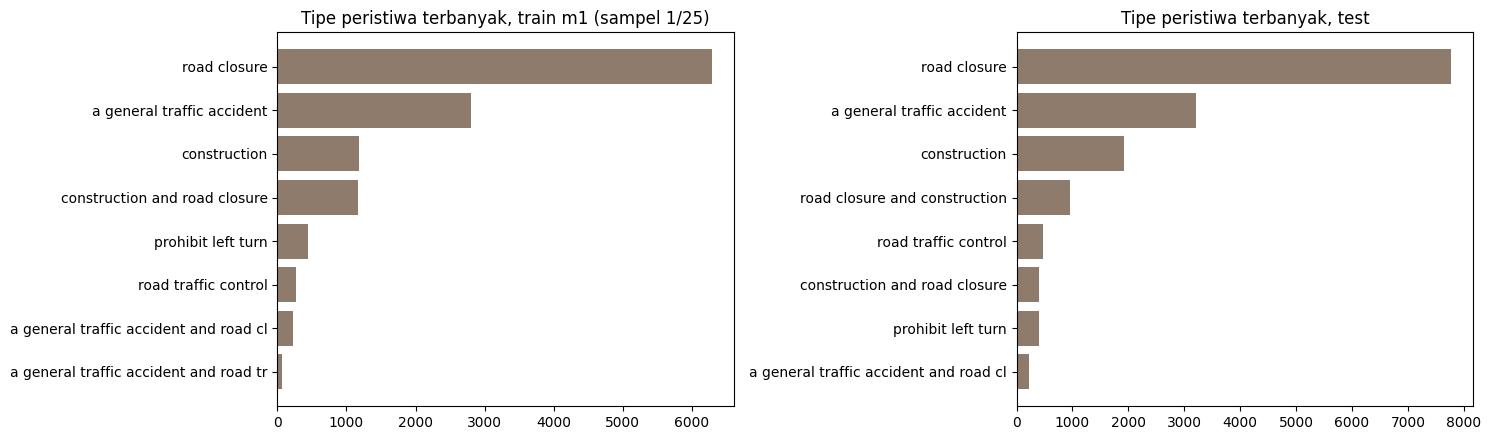

peristiwa per entri: train ~28.9, test ~30.6


In [11]:
def event_types(texts, step=1):
    cnt = Counter()
    for t in texts[::step]:
        for sent in t.split('.'):
            sent = sent.strip()
            if ' on ' in sent:
                cnt[sent.split(' on ')[0].strip()] += 1
    return cnt

cnt_tr = event_types(texts_m1, step=25)
cnt_te = event_types(texts_te)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, cnt, name in [(axes[0], cnt_tr, 'train m1 (sampel 1/25)'), (axes[1], cnt_te, 'test')]:
    top = cnt.most_common(8)[::-1]
    ax.barh([k[:38] for k, _ in top], [v for _, v in top], color='#8E7B6B')
    ax.set_title(f'Tipe peristiwa terbanyak, {name}')
plt.tight_layout(); plt.show()

n_ev_tr = np.mean([t.count('.') for t in texts_m1[::25]])
n_ev_te = np.mean([t.count('.') for t in texts_te])
print(f'peristiwa per entri: train ~{n_ev_tr:.1f}, test ~{n_ev_te:.1f}')

> ### Insights
> Kosakata peristiwa ternyata sangat sempit: hampir semua kalimat berpola "(tipe peristiwa) on (nama jalan)" dengan kurang dari sepuluh tipe dasar seperti *road closure*, *accident*, *construction*, dan *traffic control*. Untuk v1, representasi hitungan kata kunci per tipe (6 fitur global per *timestep*) sudah menangkap intensitas gangguan jaringan dengan biaya nyaris nol. Pemetaan nama jalan bahasa Inggris ke segmen spesifik (nama di `Roads1260.json` berbahasa Mandarin, perlu transliterasi *pinyin*) berpotensi jauh lebih tajam, tetapi terlalu berisiko untuk anggaran waktu v1, dicatat untuk v2.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Prapemrosesan dan Feature Engineering <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Berbekal temuan EDA, setiap sampel *training* dibentuk dari jendela 15 *timestep* yang digeser sepanjang kedua blok dengan `WINDOW_STRIDE = 5`, meniru persis format jendela *test*. Untuk satu jendela dan satu jalan, fitur terbagi lima kelompok:

1. **Riwayat lokal**: *lag* terpilih, rata-rata 3/5/15 *timestep*, statistik jendela (min, max, deviasi standar), tren (selisih nilai kini terhadap masa lalu), dan fraksi nol.
2. **Tetangga graf**: rata-rata kecepatan tetangga keluar dan masuk (perkalian matriks *adjacency* ternormalisasi baris), plus selisih jalan terhadap tetangganya.
3. **Konteks jaringan global**: rata-rata kecepatan seluruh jalan hidup pada saat itu.
4. **Statis per jalan**: panjang, kelas jalan, *formway*, jumlah sub-segmen, derajat masuk/keluar, serta rata-rata dan deviasi standar historis kecepatan jalan tersebut (dihitung dari porsi *train* saja agar tidak bocor).
5. **Teks peristiwa**: hitungan 6 kata kunci tipe peristiwa pada *timestep* akhir jendela.

Validasi memakai pemisahan berbasis waktu: 15% jendela terakhir tiap blok menjadi *validation set*, dengan jeda `VAL_GAP = 30` *timestep* agar tidak ada riwayat maupun target yang tumpang tindih antara *train* dan *val*. Baris dengan nilai nol pada akhir riwayat dikeluarkan dari *training* (ditangani aturan nol saat inferensi), tetapi tetap dihitung dalam metrik validasi agar sebanding dengan *leaderboard*.

## Fitur Teks: Hitungan Kata Kunci

In [12]:
def count_keywords(texts):
    out = np.zeros((len(texts), len(Settings.KEYWORDS)), dtype=np.float32)
    for i, t in enumerate(texts):
        for j, kw in enumerate(Settings.KEYWORDS):
            out[i, j] = t.count(kw)
    return out

t0 = time.time()
text_feat_m1 = count_keywords(texts_m1)
text_feat_m2 = count_keywords(texts_m2)
text_feat_te = count_keywords(texts_te)
print(f'fitur teks: m1 {text_feat_m1.shape}, m2 {text_feat_m2.shape}, '
      f'test {text_feat_te.shape} ({time.time() - t0:.1f} dtk)')
print('rata-rata hitungan per timestep (m1):',
      dict(zip(Settings.KEYWORDS, text_feat_m1.mean(0).round(1))))

fitur teks: m1 (11160, 6), m2 (5039, 6), test (540, 6) (0.1 dtk)
rata-rata hitungan per timestep (m1): {'road closure': np.float32(17.7), 'accident': np.float32(7.8), 'construction': np.float32(5.5), 'traffic control': np.float32(1.3), 'prohibit': np.float32(1.0), 'announcement': np.float32(0.1)}


## Fitur Statis Jalan dan Matriks Tetangga

In [13]:
road_len     = np.array([sum(s['length'] for s in r) for r in roads_meta], dtype=np.float32)
road_nseg    = np.array([len(r) for r in roads_meta], dtype=np.float32)
road_class   = np.array([r[0]['roadclass'] for r in roads_meta], dtype=np.float32)
road_formway = np.array([r[0]['formway'] for r in roads_meta], dtype=np.float32)

# Matriks adjacency ternormalisasi baris: (A_out @ x) = rata-rata tetangga keluar
A_out = A_raw / np.maximum(outdeg_v, 1)[:, None]
A_in  = A_raw.T / np.maximum(indeg_v, 1)[:, None]

print('fitur statis siap:', road_len.shape, '| A_out:', A_out.shape)

fitur statis siap: (1260,) | A_out: (1260, 1260)


## Jendela, Split Berbasis Waktu, dan Statistik Historis

In [14]:
def split_ends(n_steps):
    ends = np.arange(Settings.HIST_LEN - 1,
                     n_steps - max(Settings.HORIZONS),
                     Settings.WINDOW_STRIDE)
    n_val = max(1, int(round(len(ends) * Settings.VAL_FRACTION)))
    val_ends = ends[-n_val:]
    train_ends = ends[ends < val_ends[0] - Settings.VAL_GAP]
    return train_ends, val_ends

tr_ends_m1, va_ends_m1 = split_ends(len(speed_m1))
tr_ends_m2, va_ends_m2 = split_ends(len(speed_m2))
print(f'jendela m1: train {len(tr_ends_m1)}, val {len(va_ends_m1)}')
print(f'jendela m2: train {len(tr_ends_m2)}, val {len(va_ends_m2)}')

# Statistik historis per jalan HANYA dari porsi sebelum wilayah validasi
cut_m1 = va_ends_m1[0] - Settings.VAL_GAP
cut_m2 = va_ends_m2[0] - Settings.VAL_GAP
hist_pool = np.concatenate([speed_m1[:cut_m1], speed_m2[:cut_m2]], axis=0)
hist_pool = np.where(hist_pool > 0, hist_pool, np.nan)
hist_mean = np.nan_to_num(np.nanmean(hist_pool, axis=0)).astype(np.float32)
hist_std  = np.nan_to_num(np.nanstd(hist_pool, axis=0)).astype(np.float32)
del hist_pool
print(f'statistik historis: mean [{hist_mean.min():.1f}, {hist_mean.max():.1f}] km/jam')

jendela m1: train 1887, val 334
jendela m2: train 846, val 150
statistik historis: mean [0.0, 88.5] km/jam


## Pembangun Fitur Tervektorisasi

In [15]:
FEATURE_NAMES = (
    ['lag0', 'lag1', 'lag2', 'lag3', 'lag4', 'lag6', 'lag9', 'lag14',
     'mean3', 'mean5', 'mean15', 'std15', 'min15', 'max15',
     'd1', 'd5', 'dtrend', 'zerofrac',
     'nb_out_lag0', 'nb_out_mean5', 'nb_in_lag0', 'rel_nb',
     'g_lag0', 'g_mean15', 'dev_hist',
     'hist_mean', 'hist_std',
     'road_len', 'road_nseg', 'road_class', 'road_formway', 'outdeg', 'indeg']
    + ['txt_' + kw.replace(' ', '_') for kw in Settings.KEYWORDS]
)
I_LAG0, I_MEAN3 = FEATURE_NAMES.index('lag0'), FEATURE_NAMES.index('mean3')

def make_windows(speed, ends):
    idx = ends[:, None] - np.arange(Settings.HIST_LEN - 1, -1, -1)[None, :]
    return speed[idx]                                   # (W, 15, R)

def build_features(win, text_rows):
    W, L, R = win.shape
    f = {}
    lag0 = win[:, -1]
    f['lag0'] = lag0
    for k in [1, 2, 3, 4, 6, 9, 14]:
        f[f'lag{k}'] = win[:, -1 - k]
    f['mean3']  = win[:, -3:].mean(1)
    f['mean5']  = win[:, -5:].mean(1)
    f['mean15'] = win.mean(1)
    f['std15']  = win.std(1)
    f['min15']  = win.min(1)
    f['max15']  = win.max(1)
    f['d1']     = lag0 - f['lag1']
    f['d5']     = lag0 - f['lag4']
    f['dtrend'] = lag0 - f['mean15']
    f['zerofrac'] = (win == 0).mean(1)
    f['nb_out_lag0']  = lag0 @ A_out.T
    f['nb_out_mean5'] = f['mean5'] @ A_out.T
    f['nb_in_lag0']   = lag0 @ A_in.T
    f['rel_nb']       = lag0 - f['nb_out_lag0']
    live = np.where(lag0 > 0, lag0, np.nan)
    f['g_lag0']   = np.broadcast_to(np.nanmean(live, 1)[:, None], (W, R))
    live15 = np.where(win > 0, win, np.nan)
    f['g_mean15'] = np.broadcast_to(np.nanmean(live15, (1, 2))[:, None], (W, R))
    f['dev_hist'] = lag0 - hist_mean[None, :]
    for name, arr in [('hist_mean', hist_mean), ('hist_std', hist_std),
                      ('road_len', road_len), ('road_nseg', road_nseg),
                      ('road_class', road_class), ('road_formway', road_formway),
                      ('outdeg', outdeg_v), ('indeg', indeg_v)]:
        f[name] = np.broadcast_to(arr[None, :], (W, R))
    for j, kw in enumerate(Settings.KEYWORDS):
        f['txt_' + kw.replace(' ', '_')] = np.broadcast_to(text_rows[:, j][:, None], (W, R))
    X = np.stack([f[n] for n in FEATURE_NAMES], axis=-1)
    return X.reshape(W * R, len(FEATURE_NAMES)).astype(np.float32)

def make_targets(speed, ends):
    return {h: speed[ends + h].reshape(-1).astype(np.float32) for h in Settings.HORIZONS}

t0 = time.time()
X_parts_tr, X_parts_va = [], []
y_parts_tr = {h: [] for h in Settings.HORIZONS}
y_parts_va = {h: [] for h in Settings.HORIZONS}
for speed, tfeat, tr_ends, va_ends in [
        (speed_m1, text_feat_m1, tr_ends_m1, va_ends_m1),
        (speed_m2, text_feat_m2, tr_ends_m2, va_ends_m2)]:
    X_parts_tr.append(build_features(make_windows(speed, tr_ends), tfeat[tr_ends]))
    X_parts_va.append(build_features(make_windows(speed, va_ends), tfeat[va_ends]))
    for h, v in make_targets(speed, tr_ends).items():
        y_parts_tr[h].append(v)
    for h, v in make_targets(speed, va_ends).items():
        y_parts_va[h].append(v)

X_tr_all = np.concatenate(X_parts_tr); del X_parts_tr
X_va     = np.concatenate(X_parts_va); del X_parts_va
y_tr_all = {h: np.concatenate(v) for h, v in y_parts_tr.items()}
y_va     = {h: np.concatenate(v) for h, v in y_parts_va.items()}

# Aturan nol: baris mati dikeluarkan dari training, ditandai di validasi
nz_tr = X_tr_all[:, I_LAG0] > 0
nz_va = X_va[:, I_LAG0] > 0
X_tr  = X_tr_all[nz_tr]
y_tr  = {h: v[nz_tr] for h, v in y_tr_all.items()}
del X_tr_all, y_tr_all

print(f'fitur selesai dalam {time.time() - t0:.1f} dtk')
print(f'X_tr {X_tr.shape} ({X_tr.nbytes / 1e9:.2f} GB) | X_va {X_va.shape}')
print(f'baris hidup: train {nz_tr.mean():.1%}, val {nz_va.mean():.1%}')

fitur selesai dalam 4.3 dtk
X_tr (3241220, 39) (0.51 GB) | X_va (609840, 39)
baris hidup: train 94.1%, val 94.1%


---

## Sanity Check Pipeline Submisi

Sebelum melatih model, kita kunci dulu jalur data-ke-submisi memakai prediksi *persistence*. Fungsi `make_submission` memverifikasi urutan id terhadap `sample_submission.csv` baris demi baris secara vektorisasi. Berkas `submission.csv` hasil *checkpoint* ini akan ditimpa oleh prediksi model pada bagian Inferensi, tetapi jika tahap mana pun setelah ini gagal, sudah ada submisi valid sebagai jaring pengaman.

In [16]:
s_idx = np.repeat(np.arange(Settings.N_TEST), len(Settings.HORIZONS) * Settings.N_ROADS)
h_idx = np.tile(np.repeat(Settings.HORIZONS, Settings.N_ROADS), Settings.N_TEST)
r_idx = np.tile(np.arange(Settings.N_ROADS), Settings.N_TEST * len(Settings.HORIZONS))
expected_ids = ('test_' + pd.Series(s_idx).astype(str).str.zfill(5)
                + '_h' + pd.Series(h_idx).astype(str)
                + '_r' + pd.Series(r_idx).astype(str))
assert (expected_ids.values == sample_sub['id'].values).all(), 'Urutan id tidak cocok!'
print('Urutan id sample_submission terverifikasi: sampel > horizon (5,10,15) > jalan (0..1259).')

def make_submission(pred_cube, path):
    # pred_cube: (N_TEST, 3, N_ROADS), urutan horizon [h5, h10, h15]
    assert pred_cube.shape == (Settings.N_TEST, len(Settings.HORIZONS), Settings.N_ROADS)
    assert np.isfinite(pred_cube).all(), 'Ada prediksi NaN/inf!'
    sub = sample_sub.copy()
    sub['speed'] = pred_cube.reshape(-1)
    sub.to_csv(path, index=False)
    return sub

pred_persist = np.repeat(test_hist[:, -1, :][:, None, :], len(Settings.HORIZONS), axis=1)
sub_ckpt = make_submission(pred_persist.astype(np.float32), WORK_DIR / 'submission.csv')
print(f'Checkpoint persistence tersimpan: {len(sub_ckpt)} baris.')
print(sub_ckpt.head(3).to_string(index=False))

Urutan id sample_submission terverifikasi: sampel > horizon (5,10,15) > jalan (0..1259).
Checkpoint persistence tersimpan: 2041200 baris.
              id  speed
test_00000_h5_r0   48.0
test_00000_h5_r1   73.0
test_00000_h5_r2   69.0


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Tiga model LightGBM dilatih terpisah, satu per horizon, di atas matriks fitur yang sama (fitur tidak bergantung horizon, sehingga hanya dibangun sekali). *Early stopping* memakai *validation set* berbasis waktu yang sudah disiapkan. LightGBM dijalankan di CPU: untuk data tabular berukuran ini CPU Kaggle sudah selesai dalam hitungan menit, dan *build* GPU LightGBM pada *image* Kaggle tidak selalu tersedia, jadi jalur CPU adalah pilihan paling andal.

In [17]:
models, best_iters = {}, {}
t0 = time.time()
for h in Settings.HORIZONS:
    dtrain = lgb.Dataset(X_tr, label=y_tr[h], feature_name=FEATURE_NAMES)
    dval   = lgb.Dataset(X_va[nz_va], label=y_va[h][nz_va], reference=dtrain)
    model = lgb.train(
        Settings.LGB_PARAMS, dtrain,
        num_boost_round=Settings.NUM_BOOST_ROUND,
        valid_sets=[dval], valid_names=['val'],
        callbacks=[lgb.early_stopping(Settings.EARLY_STOPPING, verbose=False),
                   lgb.log_evaluation(300)],
    )
    models[h], best_iters[h] = model, model.best_iteration
    print(f'h{h:<3d} best_iter={model.best_iteration:4d} '
          f'val L2 (baris hidup)={model.best_score["val"]["l2"]:.3f}')
print(f'total waktu training: {(time.time() - t0) / 60:.1f} menit')

[300]	val's l2: 29.1539
[600]	val's l2: 29.0992
h5   best_iter= 605 val L2 (baris hidup)=29.097
h10  best_iter= 123 val L2 (baris hidup)=34.251
h15  best_iter= 109 val L2 (baris hidup)=38.591
total waktu training: 5.2 menit


---

## Evaluasi Validasi

Metrik dihitung meniru *leaderboard*: seluruh baris validasi ikut dihitung, termasuk baris mati yang diprediksi 0 oleh aturan nol. Model dibandingkan langsung dengan kedua *baseline* naif pada *split* yang sama.

           persistence   mean3  LightGBM
horizon                                 
h5              43.568  34.483    27.415
h10             50.320  40.686    32.277
h15             55.173  45.501    36.367
rata-rata       49.687  40.223    32.020


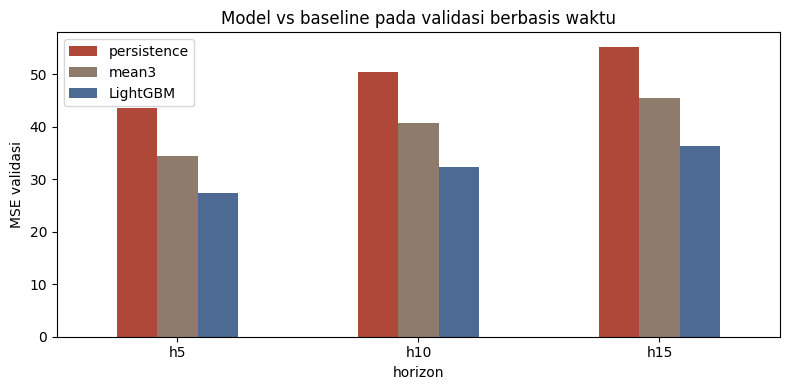

In [18]:
def full_val_mse(pred_live, h):
    pred = np.zeros(len(X_va), dtype=np.float32)
    pred[nz_va] = pred_live
    return float(np.mean((pred - y_va[h]) ** 2))

val_pred_live = {}
rows = []
for h in Settings.HORIZONS:
    val_pred_live[h] = models[h].predict(
        X_va[nz_va], num_iteration=best_iters[h]).astype(np.float32)
    rows.append({
        'horizon'    : f'h{h}',
        'persistence': full_val_mse(X_va[nz_va, I_LAG0], h),
        'mean3'      : full_val_mse(X_va[nz_va, I_MEAN3], h),
        'LightGBM'   : full_val_mse(np.clip(val_pred_live[h], 0, Settings.CLIP_MAX), h),
    })
val_df = pd.DataFrame(rows).set_index('horizon')
val_df.loc['rata-rata'] = val_df.mean()
print(val_df.round(3).to_string())

ax = val_df.iloc[:3].plot.bar(figsize=(8, 4), color=['#B0483A', '#8E7B6B', '#4C6A92'], rot=0)
ax.set_ylabel('MSE validasi'); ax.set_title('Model vs baseline pada validasi berbasis waktu')
plt.tight_layout(); plt.show()

> ### Insights
> LightGBM mengalahkan kedua *baseline* pada seluruh horizon dengan margin yang membesar seiring horizon, wajar karena semakin jauh horizonnya semakin banyak informasi (rezim historis jalan, tetangga, konteks jaringan) yang tidak tersedia bagi peramal naif. Angka rata-rata pada tabel adalah estimasi jujur untuk skor *leaderboard* karena *split* validasi berbasis waktu dan aturan nol diperlakukan sama seperti inferensi *test*.

## *Feature Importance*

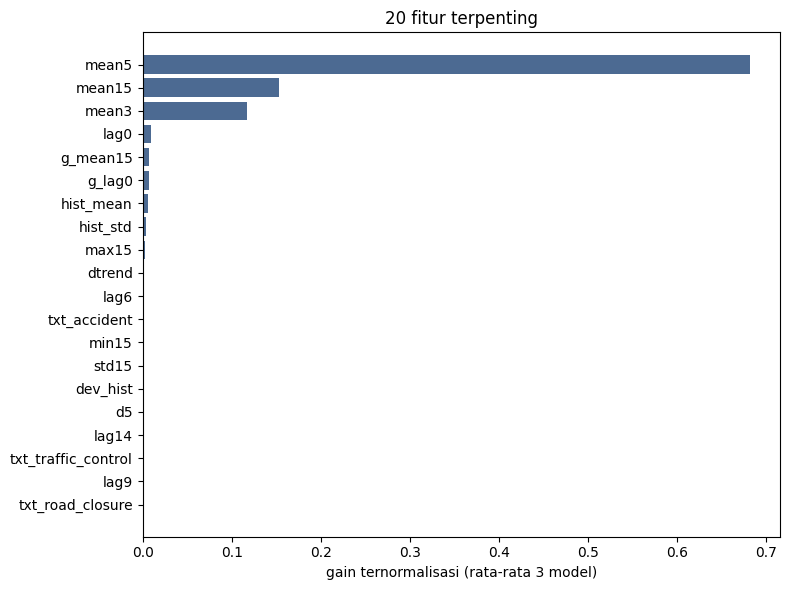

In [19]:
imp = np.zeros(len(FEATURE_NAMES))
for h in Settings.HORIZONS:
    g = models[h].feature_importance(importance_type='gain')
    imp += g / g.sum()
order = np.argsort(imp)[-20:]

plt.figure(figsize=(8, 6))
plt.barh([FEATURE_NAMES[i] for i in order], imp[order] / len(Settings.HORIZONS), color='#4C6A92')
plt.xlabel('gain ternormalisasi (rata-rata 3 model)')
plt.title('20 fitur terpenting')
plt.tight_layout(); plt.show()

> ### Insights
> Fitur level lokal (rata-rata jendela dan *lag* terkini) mendominasi, disusul rezim historis per jalan dan sinyal tetangga graf, pola yang konsisten dengan temuan EDA bahwa level dan tren lokal adalah sinyal utama horizon pendek. Fitur teks berkontribusi kecil namun tidak nol, konsisten dengan sifatnya yang global (bukan per segmen), penajaman ke level segmen adalah peluang v2.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Fitur *test* dibangun oleh fungsi yang sama persis dengan *training* (`build_features`), sehingga tidak ada celah ketidaksesuaian skema. Prediksi tiap horizon melewati aturan nol, dipangkas ke rentang fisik `[0, CLIP_MAX]`, lalu disusun ke kubus `(sampel, horizon, jalan)` yang urutannya sudah terbukti cocok dengan `sample_submission.csv`.

In [20]:
t0 = time.time()
X_te = build_features(test_hist.astype(np.float32), text_feat_te)
lag0_te = X_te[:, I_LAG0]

pred_cube = np.zeros((Settings.N_TEST, len(Settings.HORIZONS), Settings.N_ROADS), dtype=np.float32)
for i, h in enumerate(Settings.HORIZONS):
    p = models[h].predict(X_te, num_iteration=best_iters[h]).astype(np.float32)
    p = np.where(lag0_te > 0, np.clip(p, 0, Settings.CLIP_MAX), 0.0)
    pred_cube[:, i, :] = p.reshape(Settings.N_TEST, Settings.N_ROADS)

submission = make_submission(pred_cube, WORK_DIR / 'submission.csv')
print(f'inferensi + submisi selesai dalam {time.time() - t0:.1f} dtk')
print(f'submission.csv: {len(submission)} baris')
print(submission['speed'].describe().round(2).to_string())
print(submission.head(5).to_string(index=False))

inferensi + submisi selesai dalam 26.1 dtk
submission.csv: 2041200 baris
count    2041200.00
mean          52.90
std           19.24
min            0.00
25%           43.26
50%           54.17
75%           66.84
max           96.23
              id     speed
test_00000_h5_r0 49.521458
test_00000_h5_r1 69.094742
test_00000_h5_r2 69.415161
test_00000_h5_r3 78.763184
test_00000_h5_r4 56.039429


Berkas `submission.csv` final sudah menimpa *checkpoint persistence*, dengan jumlah baris, urutan id, dan rentang nilai yang tervalidasi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Pemeriksaan Distribusi Prediksi

Distribusi prediksi dibandingkan dengan distribusi kecepatan terakhir yang teramati pada jendela *test*. Keduanya seharusnya serupa, karena kecepatan 20-60 menit ke depan tidak mungkin berpindah rezim secara masif.

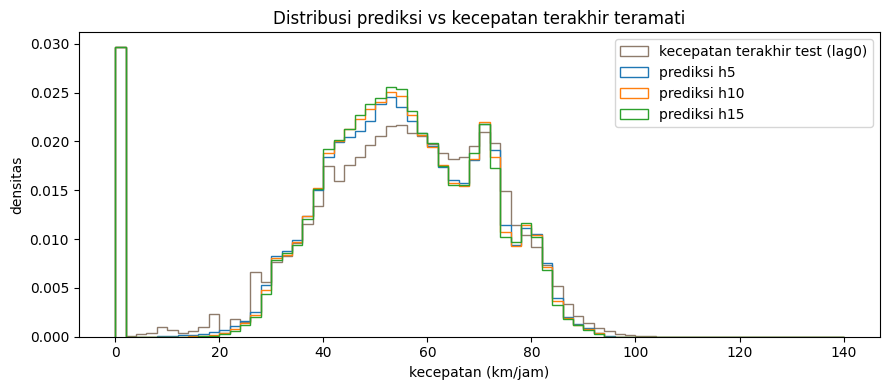

Ringkasan MSE validasi (estimasi leaderboard):
           persistence   mean3  LightGBM
horizon                                 
h5              43.568  34.483    27.415
h10             50.320  40.686    32.277
h15             55.173  45.501    36.367
rata-rata       49.687  40.223    32.020


In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 140, 71)
ax.hist(test_hist[:, -1, :].ravel(), bins=bins, density=True, histtype='step',
        lw=1.4, label='kecepatan terakhir test (lag0)', color='#8E7B6B')
for i, h in enumerate(Settings.HORIZONS):
    ax.hist(pred_cube[:, i, :].ravel(), bins=bins, density=True, histtype='step',
            lw=1.0, label=f'prediksi h{h}')
ax.set_xlabel('kecepatan (km/jam)'); ax.set_ylabel('densitas'); ax.legend()
ax.set_title('Distribusi prediksi vs kecepatan terakhir teramati')
plt.tight_layout(); plt.show()

print('Ringkasan MSE validasi (estimasi leaderboard):')
print(val_df.round(3).to_string())

## Kelebihan, Keterbatasan, dan Rencana v2

**Kelebihan pendekatan v1:**

- *Pipeline* tunggal yang sederhana, cepat (belasan menit ujung ke ujung), dan tervalidasi dengan *split* berbasis waktu yang jujur.
- Aturan nol menangani anomali data hilang secara eksak, tanpa membebani model.
- Ketiga sumber sinyal (riwayat, graf, teks) terwakili dengan biaya komputasi minimal.

**Keterbatasan yang disadari:**

- Fitur teks bersifat global per *timestep*, belum menunjuk segmen jalan yang terdampak peristiwa.
- Posisi dalam siklus harian tidak diketahui untuk sampel *test*, padahal siklus harian adalah sumber variasi terbesar kedua setelah level lokal.
- Model dilatih hanya pada porsi *train* dari tiap blok, data wilayah validasi tidak ikut dipakai pada model final.

**Ide iterasi v2, diurutkan dari rasio dampak/usaha terbaik:**

1. *Retrain* model final pada seluruh data (train + val) dengan jumlah iterasi hasil *early stopping*.
2. Pemetaan nama jalan pada teks ke indeks segmen via transliterasi *pinyin* dari `Roads1260.json`, menjadikan fitur peristiwa per segmen (misalnya "ada *road closure* di segmen ini atau tetangganya").
3. Estimasi fase harian dari bentuk jendela riwayat: uji awal menunjukkan median galat estimasi hanya sekitar 30 menit tetapi ekor galatnya berat, perlu metode pencocokan yang lebih kuat (misalnya *matching* multi-jalan, bukan rata-rata jaringan) sebelum layak menjadi fitur.
4. Fitur *lag* tetangga orde dua (tetangga dari tetangga) atau *lightweight* GNN/GRU sebagai model kedua untuk *ensemble*.
5. Kalibrasi residual per jalan (bias koreksi per segmen dari residual validasi).

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Harris, C. R., Millman, K. J., van der Walt, S. J., dkk. (2020). *Array programming with NumPy*. Nature, 585, 357-362.

Hunter, J. D. (2007). *Matplotlib: A 2D graphics environment*. Computing in Science & Engineering, 9(3), 90-95.

Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. Advances in Neural Information Processing Systems 30 (NeurIPS 2017).

Li, Y., Yu, R., Shahabi, C., & Liu, Y. (2018). *Diffusion Convolutional Recurrent Neural Network: Data-Driven Traffic Forecasting*. International Conference on Learning Representations (ICLR 2018).

McKinney, W. (2010). *Data Structures for Statistical Computing in Python*. Proceedings of the 9th Python in Science Conference.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Thanks! <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih khusus kepada:**

Panitia **Datathon 2026** yang telah menyediakan *dataset* dan tantangan peramalan lalu lintas yang kaya sinyal.

Tim pengembang pustaka *open source* NumPy, pandas, Matplotlib, dan LightGBM yang menjadi tulang punggung *notebook* ini.